In [1]:
import numpy as np
import matplotlib.pyplot as plt

from paper2026 import Osteostat, Mechanostat
from paper2026 import get_time_vectors, get_default_initial_conditions, get_drop_force_vector, get_day_index
from paper2026 import configure_plotting_for_paper

In [2]:
figsize = configure_plotting_for_paper()

## Comparing Osteostat and Mechanostat in long-time scale unloading/reloading

### Define model parameters and initial conditions 

In [3]:
# Time-related parameters
n_years = 80
t_reload = 30*365. # in days, time point when to reaload after unloading
t_stop = n_years*365. # in days
t_inc = 1.0 # in days, timestep for solver

F0 = 0.12 # [kN] Initial force

f_bm0 = 0.85 # [-] initial bone volume fraction

n_ramp = 1 # number of increments for force to change between down-up or up-down transition.

solver='dopri5'

simulation_force_factor = [0.3, 0.65]
simulation_key_string = ['70%', '35%']

In [4]:
t_eval, t_force = get_time_vectors(t_stop=t_stop, t_inc=t_inc, t_inc_force=t_inc)

In [5]:
models = {'osteostat': Osteostat(f_bm0=f_bm0),
           'mechanostat': Mechanostat(f_bm0=f_bm0)}

In [6]:
initial_conditions=[]
for key in models:
    model = models[key]
    
    initial_conditions.append(get_default_initial_conditions(model, F0, f_bm0))
    print(initial_conditions[-1])

[0.85, 3.002076124567474e-05, 24000.0]
[0.85, 3.002076124567474e-05, 24000.0]


### Solve the model ODEs 

In [7]:
# reload-point
reload_index = get_day_index(t_reload, t_inc)

# solve all model-force situations
for i in range(len(simulation_force_factor)):
    
    force = get_drop_force_vector(F0=F0, 
                                  F_drop=simulation_force_factor[i]*F0,
                                 idx_up=reload_index,
                                 force_length=t_force.size,
                                 n_ramp=n_ramp)
    
    for j, key in enumerate(models):
        model = models[key]
        model.solve(t_eval, initial_conditions[j], force , t_force, simulation_key_string[i], solver=solver)

using ode() with dopri5
100%|████████████████████████████████████████████████▉| 29200/29201 [00:06<00:00, 4435.43it/s]
Success
adding results with key 70%
100%|████████████████████████████████████████████████| 29201/29201 [00:01<00:00, 28689.55it/s]
using ode() with dopri5
100%|████████████████████████████████████████████████▉| 29200/29201 [00:06<00:00, 4430.90it/s]
Success
adding results with key 70%
100%|████████████████████████████████████████████████| 29201/29201 [00:01<00:00, 28805.10it/s]
using ode() with dopri5
100%|████████████████████████████████████████████████▉| 29200/29201 [00:06<00:00, 4466.29it/s]
Success
adding results with key 35%
100%|████████████████████████████████████████████████| 29201/29201 [00:01<00:00, 28697.98it/s]
using ode() with dopri5
100%|████████████████████████████████████████████████▉| 29200/29201 [00:06<00:00, 4402.95it/s]
Success
adding results with key 35%
100%|████████████████████████████████████████████████| 29201/29201 [00:01<00:00, 28554.24it/s]


### Plot a single variable 

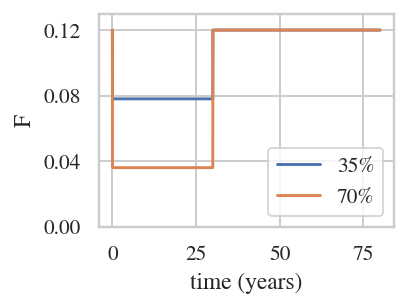

In [8]:
fig = plt.figure(1, figsize=(figsize[0], figsize[1] * 1))
axs = fig.subplots(nrows=1, ncols=1)
fig.set_tight_layout(True)

models['osteostat'].plot_result(key_str='70%',
                  variables=['F'],
                  compare_results={'35%': models['osteostat'].results.get('35%')},
                  axs=axs)
axs.set_ylim([0, 0.13]);
axs.set_yticks([0,  0.04,  0.08,  0.12]);

### Plot multiple variables 

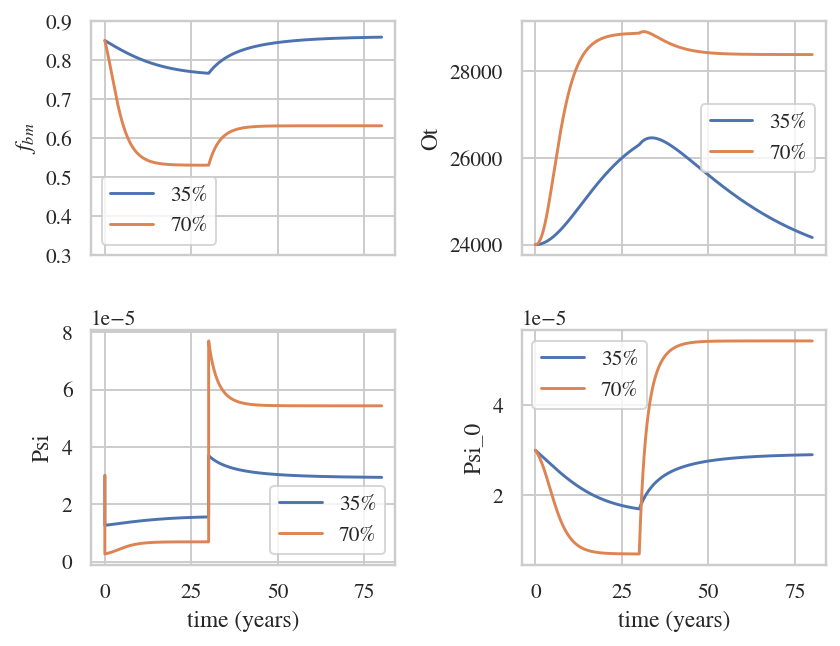

In [9]:
fig = plt.figure(1, figsize=(2*figsize[0], figsize[1] * 2))
fig.set_tight_layout(True)
axs = fig.subplots(nrows=2, ncols=2, sharex=True)

models['osteostat'].plot_result(key_str='70%',
                  variables=['f_bm', 'Ot', 'Psi', 'Psi_0'],
                  compare_results={'35%': models['osteostat'].results.get('35%')},
                   axs=axs)
axs[0,0].set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
axs[0,0].set_ylabel('$f_{bm}$');

for ax in axs.flatten()[:-2]: ax.set_xlabel(None)

### Compare Osteostat and Mechanostat

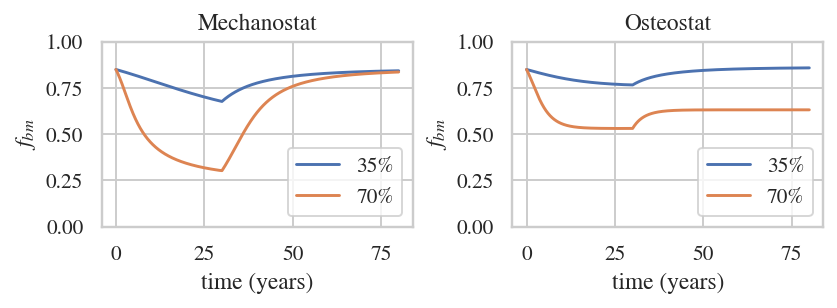

In [10]:
variables=['f_bm']

fig = plt.figure(1, figsize=(figsize[0]*2, figsize[1] * len(variables)))
axs = fig.subplots(nrows=len(variables), ncols=2)
fig.set_tight_layout(True)

mstat = models['mechanostat']
mstat.plot_result('70%',
                  variables=variables,
                  compare_results={'35%': mstat.results.get('35%')},
                  axs=axs[0])

axs[0].set_ylim([0, 1])
axs[0].set_ylabel('$f_{bm}$')
axs[0].legend(loc='lower right')
axs[0].set_title('Mechanostat');

ostat = models['osteostat']
ostat.plot_result('70%',
                  variables=variables,
                  compare_results={'35%': ostat.results.get('35%')},
                  axs=axs[1])

axs[1].set_ylim([0, 1])
axs[1].set_ylabel('$f_{bm}$')
axs[1].legend(loc='lower right')
axs[1].set_title('Osteostat');
